# Black-Scholes PINN Implementation

In this notebook, I implemented a Physics-Informed Neural Network (PINN) to approximate the solution of the Black-Scholes PDE for a European call option.

The aim is to train a neural network to learn the option price $V(S, \tau)$, where:

- $S$ is the stock price
- $\tau$ is the time to maturity
- $V(S, \tau)$ is the option value

I used $\tau = T - t$, so the Black-Scholes PDE is written in forward time-to-maturity form:

$$\frac{\partial V}{\partial \tau}=\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}+ rS \frac{\partial V}{\partial S}- rV$$

The PINN is trained by minimizing a loss function made up of four parts:

1. PDE loss: measures how well the neural network satisfies the Black-Scholes PDE inside the domain.
2. Lower boundary loss: enforces the option price at the lower stock price boundary.
3. Upper boundary loss: enforces the option price at the upper stock price boundary.
4. Terminal payoff loss: enforces the European call payoff at $\tau = 0$.

For a European call option, the terminal payoff is:

$V(S,0) = \max(S-K,0)$

The boundary conditions used are:

$$V(0,t) = 0, V(S \to \infty,t) = S - Ke^{-r\tau}$$

The model uses the input pair $(S, \tau)$ and outputs an approximation to the option price $V(S, \tau)$.

The fixed parameter set used in this notebook is:

- Strike price: $K = 100$
- Maturity: $T = 1$
- Risk-free rate: $r = 0.05$
- Volatility: $\sigma = 0.2$
- $S_{max} = 3 \cdot K$

Once the PINN is trained, I compared its predicted option prices against the analytical Black-Scholes solution.

In [98]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import gc
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm
from src.metrics import error_summary
from src.metrics import mse, rmse, mae, max_abs_error, relative_l2_error
import pandas as pd

torch.set_num_threads(1)

import sys
sys.path.append("..")
from src.pinn import BlackScholesPINN

In [29]:
# Defining parameters.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [41]:
# Generating training points for the PINN model.

def generate_training_points(N_f, N_ic, N_bc):
    S_f = torch.rand(N_f, 1) * S_max
    tau_f = torch.rand(N_f, 1) * T

    S_ic = torch.rand(N_ic, 1) * S_max
    tau_ic = torch.zeros_like(S_ic)
    V_ic = torch.clamp(S_ic - K, min=0.0)

    tau_lb = torch.rand(N_bc, 1) * T
    S_lb = torch.zeros_like(tau_lb)
    V_lb = torch.zeros_like(tau_lb)

    tau_ub = torch.rand(N_bc, 1) * T
    S_ub = torch.full_like(tau_ub, S_max)
    V_ub = S_max - K * torch.exp(-r * tau_ub)

    return S_f, tau_f, S_ic, tau_ic, V_ic, S_lb, tau_lb, V_lb, S_ub, tau_ub, V_ub

In [42]:
# Defining the loss function for the PINN model.

def pinn_loss(model, training_data):
    S_f, tau_f, S_ic, tau_ic, V_ic, S_lb, tau_lb, V_lb, S_ub, tau_ub, V_ub = training_data

    residual = model.pde_residual(S_f, tau_f, r, sigma)
    loss_pde = torch.mean((residual / K) ** 2)

    V_ic_pred = model(S_ic, tau_ic)
    loss_ic = torch.mean(((V_ic_pred - V_ic) / K) ** 2)

    V_lb_pred = model(S_lb, tau_lb)
    loss_lb = torch.mean(((V_lb_pred - V_lb) / K) ** 2)

    V_ub_pred = model(S_ub, tau_ub)
    loss_ub = torch.mean(((V_ub_pred - V_ub) / K) ** 2)

    total_loss = loss_pde + loss_ic + loss_lb + loss_ub

    return total_loss, loss_pde, loss_ic, loss_lb, loss_ub

In [ ]:
# Training the PINN model.

model = BlackScholesPINN(
    layers=[2, 32, 32, 32, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_history = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc
    )

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = pinn_loss(
        model,
        training_data
    )

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.408550e+00, PDE=2.781462e-04, IC=9.529012e-01, LB=8.879219e-03, UB=4.446491e+00
Epoch 500: Total=4.767171e-02, PDE=6.061899e-03, IC=3.129674e-02, LB=7.839068e-03, UB=2.473994e-03
Epoch 1000: Total=6.365439e-03, PDE=1.566328e-03, IC=4.140472e-03, LB=2.407521e-04, UB=4.178870e-04
Epoch 1500: Total=3.491845e-03, PDE=7.703713e-04, IC=2.167582e-03, LB=1.534568e-04, UB=4.004349e-04
Epoch 2000: Total=1.320048e-03, PDE=2.033833e-04, IC=9.651012e-04, LB=4.894140e-05, UB=1.026226e-04
Epoch 2500: Total=7.232381e-04, PDE=1.237927e-04, IC=5.632823e-04, LB=2.994085e-05, UB=6.222254e-06
Epoch 3000: Total=9.358266e-04, PDE=1.040530e-04, IC=7.121553e-04, LB=7.580326e-05, UB=4.381509e-05
Epoch 3500: Total=5.820668e-04, PDE=9.134344e-05, IC=4.514601e-04, LB=3.422757e-05, UB=5.035640e-06
Epoch 4000: Total=6.552761e-04, PDE=7.234290e-05, IC=4.718072e-04, LB=2.568680e-05, UB=8.543910e-05
Epoch 4500: Total=3.917881e-04, PDE=5.310722e-05, IC=3.111824e-04, LB=2.227650e-05, UB=5.221927e-06


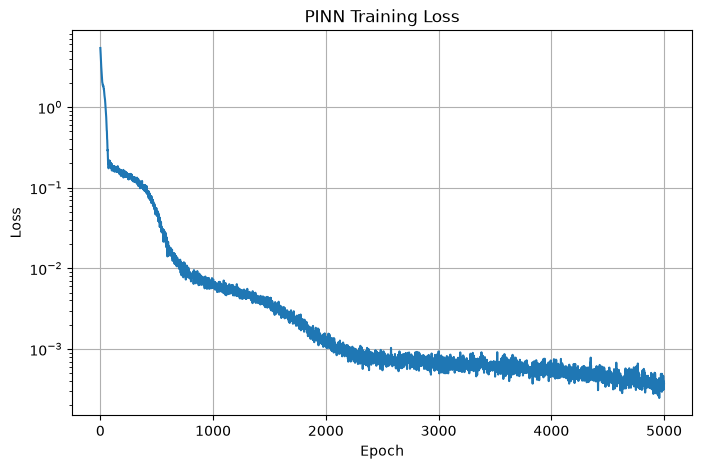

In [53]:
# Visualizing the training loss history.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Loss")
plt.grid(True)
plt.show()

In [54]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model.eval()
with torch.no_grad():
    V_pred = model(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

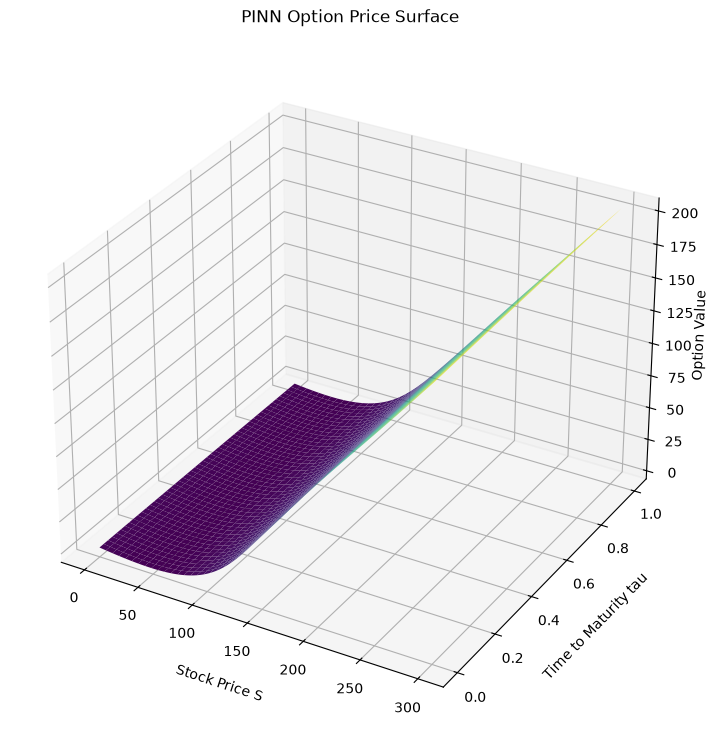

In [55]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface, cmap="viridis")

ax.set_title("PINN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

In [57]:
# To evaluate the PINN model against the analytical Black-Scholes solution, we can compute the analytical solution for a range of stock prices and times to maturity, and then compare it with the predictions from the trained PINN model.
# First define a function to compute the Black-Scholes call option price for a grid of stock prices and times to maturity.

def black_scholes_call_grid(S, tau, K, r, sigma):
    S = np.asarray(S, dtype=float)
    tau = np.asarray(tau, dtype=float)

    price = np.zeros_like(S)

    # At expiry: payoff
    expiry = tau <= 1e-12
    price[expiry] = np.maximum(S[expiry] - K, 0)

    # Away from expiry
    valid = (tau > 1e-12) & (S > 0)

    S_valid = S[valid]
    tau_valid = tau[valid]

    d1 = (
        np.log(S_valid / K)
        + (r + 0.5 * sigma**2) * tau_valid
    ) / (sigma * np.sqrt(tau_valid))

    d2 = d1 - sigma * np.sqrt(tau_valid)

    price[valid] = (
        S_valid * norm.cdf(d1)
        - K * np.exp(-r * tau_valid) * norm.cdf(d2)
    )

    return price

In [61]:
# Then apply this function to the same grid of stock prices and times to maturity used for the PINN evaluation, and compute the analytical option prices.

V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)

# Checking that the shapes of the PINN predictions and the analytical solution match, which is important for comparison and visualization.
print(V_surface.shape)
print(V_exact_surface.shape)

abs_error_surface = np.abs(V_surface - V_exact_surface)

(100, 50)
(100, 50)


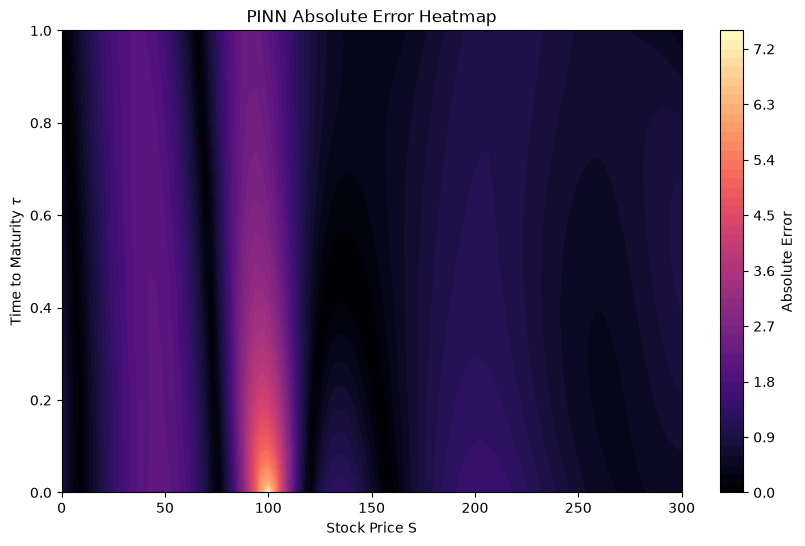

In [62]:
# Now, plot the absolute error heatmap between the PINN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [63]:
# Plotting some key metrics for a more quantitative assessment of the PINN's performance against the analytical solution.

metrics = error_summary(V_surface, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,1.728640
1,RMSE,1.314777
2,MAE,1.054653
3,Max Abs Error,7.353555
4,Relative L2 Error,0.013604


The maximum absolute error occurs near the strike price $K=100$ and $\tau = 0$. An EU call payoff has a kink at this point which the PINN struggles to deal with given it uses smooth $\tanh()$ activation functions. Away from this point the error is much smaller.

## Tuning PINN

Here I will do some basic tuning to see if I can improve performance. 

* First I wll tune the architecture by increasing the number of neurons (i.e using a wider network).
* Then I will add a learning rate scheduler.
* Then I will increase the weight of the initial condition loss in my loss function, since this is the point where the max loss is achieved.

In [ ]:
# Tuned PINN: wider network.

model_wide = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide = torch.optim.Adam(model_wide.parameters(), lr=1e-3)

loss_history_wide = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc
    )

    optimizer_wide.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = pinn_loss(
        model_wide,
        training_data
    )

    total_loss.backward()
    optimizer_wide.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide()

    loss_history_wide.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.038967e+00, PDE=4.962319e-03, IC=8.911827e-01, LB=5.365695e-04, UB=4.142285e+00


In [ ]:
# Create evaluation grid for tuned model.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide.eval()
with torch.no_grad():
    V_pred = model_wide(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()


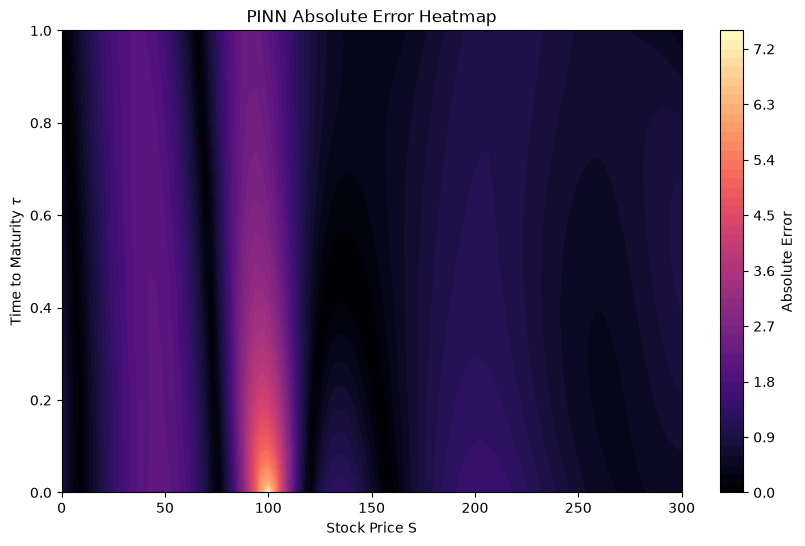

In [ ]:
# Generating an error heatmap for the tuned model to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [ ]:
# Plotting some key metrics for a more quantitative assessment of the tuned PINN's performance against the analytical solution.

metrics_wide = error_summary(V_surface, V_exact_surface)

metrics_wide_table = pd.DataFrame({
    "Metric": metrics_wide.keys(),
    "Value": metrics_wide.values()
})

metrics_wide_table

,Metric,Value
0,MSE,0.448859
1,RMSE,0.669969
2,MAE,0.625369
3,Max Abs Error,3.105676
4,Relative L2 Error,0.006932


Clearly the performance has increased by using a wider network. Now I will add a learning rate scheduler to gradually reduce the learning rate as training goes on. This helps to make fine adjustments later on.



In [ ]:
# Tuned PINN: wider network with learning rate scheduler.

model_wide_scheduler = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide_scheduler = torch.optim.Adam(
    model_wide_scheduler.parameters(),
    lr=1e-3
)

scheduler_wide = torch.optim.lr_scheduler.StepLR(
    optimizer_wide_scheduler,
    step_size=2000,
    gamma=0.5
)

loss_history_wide_scheduler = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide_scheduler():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc
    )

    optimizer_wide_scheduler.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = pinn_loss(
        model_wide_scheduler,
        training_data
    )

    total_loss.backward()
    optimizer_wide_scheduler.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide_scheduler()

    scheduler_wide.step()

    loss_history_wide_scheduler.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_wide_scheduler.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=6.436255e+00, PDE=2.333772e-03, IC=1.236663e+00, LB=1.861785e-02, UB=5.178640e+00, LR=1.00e-03
Epoch 500: Total=9.942139e-03, PDE=1.594182e-03, IC=7.307801e-03, LB=9.560476e-04, UB=8.410851e-05, LR=1.00e-03
Epoch 1000: Total=1.056117e-03, PDE=3.839810e-04, IC=5.863315e-04, LB=2.991748e-05, UB=5.588671e-05, LR=1.00e-03
Epoch 1500: Total=5.179228e-04, PDE=1.799991e-04, IC=3.071700e-04, LB=1.807017e-05, UB=1.268350e-05, LR=1.00e-03
Epoch 2000: Total=2.819821e-04, PDE=7.139906e-05, IC=1.894423e-04, LB=1.565132e-05, UB=5.489400e-06, LR=5.00e-04
Epoch 2500: Total=2.415996e-04, PDE=6.015064e-05, IC=1.690378e-04, LB=9.781424e-06, UB=2.629733e-06, LR=5.00e-04
Epoch 3000: Total=2.000537e-04, PDE=6.511548e-05, IC=1.168965e-04, LB=1.278573e-05, UB=5.255950e-06, LR=5.00e-04
Epoch 3500: Total=1.957144e-04, PDE=5.846311e-05, IC=1.237969e-04, LB=1.018167e-05, UB=3.272770e-06, LR=5.00e-04
Epoch 4000: Total=2.300505e-04, PDE=5.589643e-05, IC=1.683606e-04, LB=3.489113e-06, UB=2.304297e-06,

In [ ]:
# Create evaluation grid for model with learning rate scheduler.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide_scheduler.eval()
with torch.no_grad():
    V_pred = model_wide_scheduler(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()


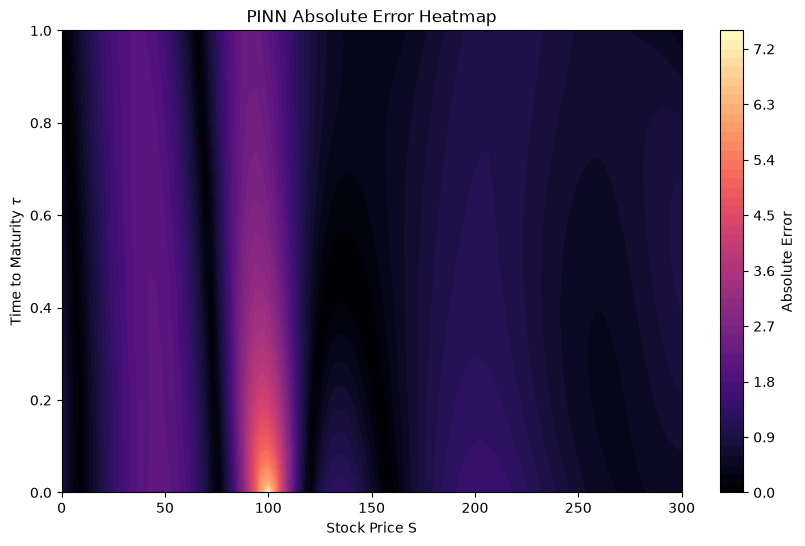

In [ ]:
# Generating an error heatmap for the model with learning rate scheduler to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [ ]:
# Plotting some key metrics for a more quantitative assessment of the PINN with learning rate scheduler's performance against the analytical solution.

metrics_wide_scheduler = error_summary(V_surface, V_exact_surface)

metrics_wide_scheduler_table = pd.DataFrame({
    "Metric": metrics_wide_scheduler.keys(),
    "Value": metrics_wide_scheduler.values()
})

metrics_wide_scheduler_table

,Metric,Value
0,MSE,0.314211
1,RMSE,0.560545
2,MAE,0.362978
3,Max Abs Error,5.127146
4,Relative L2 Error,0.005800


This slightly improved the L2 error but increased max absolute error. To try and combat the max error I will increase the weight of initial condition loss in the loss function.

In [ ]:
# Defining the modified loss function for the PINN model.

def pinn_loss_modified(model, training_data):
    S_f, tau_f, S_ic, tau_ic, V_ic, S_lb, tau_lb, V_lb, S_ub, tau_ub, V_ub = training_data

    modified_residual = model.pde_residual(S_f, tau_f, r, sigma)
    modified_loss_pde = torch.mean((modified_residual / K) ** 2)

    V_ic_pred = model(S_ic, tau_ic)
    modified_loss_ic = torch.mean(((V_ic_pred - V_ic) / K) ** 2)

    V_lb_pred = model(S_lb, tau_lb)
    modified_loss_lb = torch.mean(((V_lb_pred - V_lb) / K) ** 2)

    V_ub_pred = model(S_ub, tau_ub)
    modified_loss_ub = torch.mean(((V_ub_pred - V_ub) / K) ** 2)

    modified_total_loss = modified_loss_pde + 5 * modified_loss_ic + modified_loss_lb + modified_loss_ub # Increasing the weight of the initial condition loss to emphasize its importance in the overall training process.

    return modified_total_loss, modified_loss_pde, modified_loss_ic, modified_loss_lb, modified_loss_ub

In [ ]:
model_modified_loss = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_modified = torch.optim.Adam(model_modified_loss.parameters(), lr=1e-3)

scheduler_modified = torch.optim.lr_scheduler.StepLR(
    optimizer_modified,
    step_size=2000,
    gamma=0.5
)

loss_history_modified = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_modified():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc
    )

    optimizer_modified.zero_grad(set_to_none=True)

    modified_total_loss, modified_loss_pde, modified_loss_ic, modified_loss_lb, modified_loss_ub = pinn_loss_modified(
        model_modified_loss,
        training_data
    )

    modified_total_loss.backward()
    optimizer_modified.step()

    values = (
        modified_total_loss.detach().item(),
        modified_loss_pde.detach().item(),
        modified_loss_ic.detach().item(),
        modified_loss_lb.detach().item(),
        modified_loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_modified()

    scheduler_modified.step()

    loss_history_modified.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_modified.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=8.495860e+00, PDE=5.720265e-04, IC=8.714386e-01, LB=1.376461e-03, UB=4.136718e+00, LR=1.00e-03
Epoch 500: Total=1.500351e-02, PDE=2.619112e-03, IC=2.064294e-03, LB=7.972649e-04, UB=1.265660e-03, LR=1.00e-03
Epoch 1000: Total=2.043428e-03, PDE=2.571944e-04, IC=3.133797e-04, LB=1.879606e-04, UB=3.137437e-05, LR=1.00e-03
Epoch 1500: Total=1.903905e-03, PDE=2.464325e-04, IC=3.024565e-04, LB=1.280410e-04, UB=1.714878e-05, LR=1.00e-03
Epoch 2000: Total=1.806892e-03, PDE=2.095708e-04, IC=3.057472e-04, LB=4.638689e-05, UB=2.219886e-05, LR=5.00e-04
Epoch 2500: Total=1.427855e-03, PDE=2.042070e-04, IC=2.328980e-04, LB=3.651459e-05, UB=2.264283e-05, LR=5.00e-04
Epoch 3000: Total=8.229874e-04, PDE=1.884054e-04, IC=1.152388e-04, LB=3.855173e-05, UB=1.983626e-05, LR=5.00e-04
Epoch 3500: Total=9.905606e-04, PDE=1.410353e-04, IC=1.644474e-04, LB=1.114388e-05, UB=1.614471e-05, LR=5.00e-04
Epoch 4000: Total=6.911290e-04, PDE=1.286595e-04, IC=1.048938e-04, LB=1.920815e-05, UB=1.879225e-05,

In [ ]:
# Create evaluation grid for model with modified loss function.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_modified_loss.eval()
with torch.no_grad():
    V_pred = model_modified_loss(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()


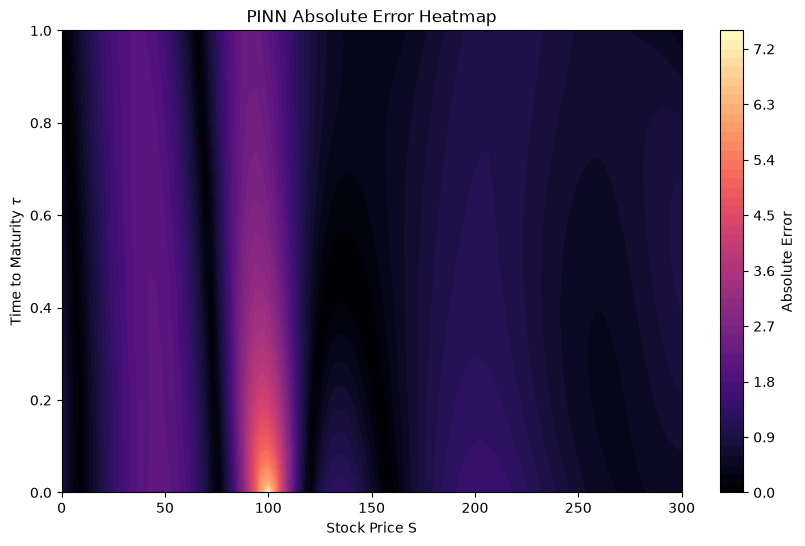

In [ ]:
# Generating an error heatmap for the model with modified loss function to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [ ]:
# Plotting some key metrics for a more quantitative assessment of the PINN with modified loss function's performance against the analytical solution.

metrics_modified_loss = error_summary(V_surface, V_exact_surface)

metrics_modified_loss_table = pd.DataFrame({
    "Metric": metrics_modified_loss.keys(),
    "Value": metrics_modified_loss.values()
})

metrics_modified_loss_table

,Metric,Value
0,MSE,0.281725
1,RMSE,0.530778
2,MAE,0.411761
3,Max Abs Error,4.608373
4,Relative L2 Error,0.005492


In [ ]:
# To compare the performance of the different PINN models, we can define a function that evaluates a given model on a grid of stock prices and times to maturity, and returns both the predicted option prices and the true analytical solution.

def evaluate_model_on_grid(model, S_grid, tau_grid):
    model.eval()

    if torch.is_tensor(S_grid):
        S_flat = S_grid.reshape(-1, 1).clone().detach().float()
        S_np = S_grid.clone().detach().numpy()
    else:
        S_flat = torch.tensor(S_grid.reshape(-1, 1), dtype=torch.float32)
        S_np = S_grid

    if torch.is_tensor(tau_grid):
        tau_flat = tau_grid.reshape(-1, 1).clone().detach().float()
        tau_np = tau_grid.clone().detach().numpy()
    else:
        tau_flat = torch.tensor(tau_grid.reshape(-1, 1), dtype=torch.float32)
        tau_np = tau_grid

    with torch.no_grad():
        pred = model(S_flat, tau_flat).detach().numpy().reshape(S_np.shape)

    true = black_scholes_call_grid(S_np, tau_np, K, r, sigma)

    return pred, true

In [ ]:
# Now, we can define a function that computes the key metrics for a given model, including MSE, RMSE, MAE, Max Absolute Error, and Relative L2 Error.

def compute_metric_row(model_name, model, architecture, scheduler, loss_type):
    pred, true = evaluate_model_on_grid(model, S_grid, tau_grid)

    return {
        "Model": model_name,
        "Architecture": architecture,
        "Scheduler": scheduler,
        "Loss": loss_type,
        "MSE": mse(pred, true),
        "RMSE": rmse(pred, true),
        "MAE": mae(pred, true),
        "Max Abs Error": max_abs_error(pred, true),
        "Relative L2 Error": relative_l2_error(pred, true)
    }

In [ ]:
# Generate a comparison table for the different PINN models.

comparison_rows = [
    compute_metric_row(
        model_name="Baseline PINN",
        model=model,
        architecture="[2, 32, 32, 32, 1]",
        scheduler="No",
        loss_type="Standard"
    ),
    compute_metric_row(
        model_name="Wider PINN",
        model=model_wide,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="No",
        loss_type="Standard"
    ),
    compute_metric_row(
        model_name="Wider PINN + LR Scheduler",
        model=model_wide_scheduler,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Standard"
    ),
    compute_metric_row(
        model_name="Wider PINN + Modified Loss",
        model=model_modified_loss,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Weighted IC"
    )
]

comparison_table = pd.DataFrame(comparison_rows)

comparison_table

,Model,Architecture,Scheduler,Loss,MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Baseline PINN,"[2, 32, 32, 32, 1]",No,Standard,1.728640,1.314777,1.054653,7.353555,0.013604
1,Wider PINN,"[2, 64, 64, 64, 1]",No,Standard,0.448859,0.669969,0.625369,3.105676,0.006932
2,Wider PINN + LR Scheduler,"[2, 64, 64, 64, 1]",StepLR,Standard,0.314211,0.560545,0.362978,5.127146,0.005800
3,Wider PINN + Modified Loss,"[2, 64, 64, 64, 1]",StepLR,Weighted IC,0.281725,0.530778,0.411761,4.608373,0.005492


The wider PINN with the modified weighted initial-condition loss produced the best overall accuracy, achieving the lowest MSE, RMSE, and relative L2 error. This suggests that increasing model capacity and placing greater emphasis on the payoff condition improves the global approximation of the Black-Scholes solution.

However, the maximum absolute error remains higher than for the wider PINN without the scheduler, indicating that the worst-case error is still localized in a difficult region of the domain, likely near the strike price and close to expiry where the payoff has a kink. Therefore, although the modified-loss model performs best overall, there remains some localized error that could potentially be reduced using adaptive sampling or residual-based attention. For now I will take the Wider PINN with modified loss function as the PINN of choice for the project, with adding adaptive sampling or RBA as potential future work.